# TinyML en ESP32-CAM — reconocimiento de dígitos MNIST
## Notebook de entrenamiento

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/daniosp/tinyml-esp32-mnist/blob/master/entrenamiento/mnist_tinyml_entrenamiento.ipynb)

> **Entorno recomendado: Google Colab.**
> Este notebook fue desarrollado y probado en Google Colab. Colab ofrece a todos el mismo
> entorno Linux + Python + TensorFlow, lo que evita problemas de instalación local
> (especialmente en Windows) y facilita reproducir los resultados.
>
> 1. Haz clic en la insignia **Abrir en Colab**.
> 2. Ejecuta las celdas **en orden, de arriba hacia abajo** (`Entorno de ejecución → Ejecutar todas`).
> 3. Los archivos descargados al final, `mnist_int8.tflite` y `model_data.h` son los mismos encontrados en el repositorio
>    (`modelos/` y `firmware/`).

### Dónde encaja este notebook en el pipeline

```
[ESTE NOTEBOOK — corre en un PC / Colab]                        [Firmware ESP32-CAM — Arduino]
MNIST → entrenar → aumentar → cuantizar int8 → .tflite → .h  ──►  cámara → 28×28 → inferencia TFLM
```

El ESP32 nunca entrena nada. Solo ejecuta la **inferencia** con los pesos congelados que exportamos aquí.

---
## 0. Entorno y reproducibilidad

Para garantizar la reproducibilidad y  poder obtener *el mismo modelo* se consideran los siguientes puntos:

1. **Versiones conocidas de las librerías**: las imprimimos y registramos abajo. Colab actualiza TensorFlow
   con el tiempo; si una versión futura de Colab rompe el notebook, instala la versión registrada
   (ver la línea `pip` comentada).
2. **Semillas aleatorias fijas**: la inicialización de pesos y el barajado de datos son aleatorios. Fijar las
   semillas hace que las ejecuciones sean repetibles *en el mismo hardware/software*. (Resultados idénticos bit a bit
   entre CPUs/GPUs distintas **no** están garantizados, porque las operaciones de punto flotante pueden
   ejecutarse en distinto orden.)
3. **Artefactos generados**: el encabezado C para el ESP32 se produce con código de este notebook; nunca se edita a mano.

In [ ]:
# --- Opcional: fijar TensorFlow si una versión futura de Colab rompe este notebook ---
# Probado con TensorFlow 2.21.0 (ver entrenamiento/requirements.txt). Si hace falta,
# descomenta la siguiente línea, ejecuta, luego Entorno de ejecución → Reiniciar sesión, y ejecuta todo de nuevo.
# !pip install -q tensorflow==2.21.0

import os, sys, platform, random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

EN_COLAB = "google.colab" in sys.modules
print("Ejecutando en Colab:", EN_COLAB)
print("Python     :", platform.python_version())
print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)

Ejecutando en Colab: True
Python     : 3.13.15
TensorFlow : 2.21.0
NumPy      : 2.1.3


In [ ]:
# Reproducibilidad: fijamos todas las fuentes de aleatoriedad que controlamos.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
# Hace deterministas las operaciones de TF (algo más lento; irrelevante para modelos tan pequeños).
tf.config.experimental.enable_op_determinism()

# Carpeta de salida para todo lo que exportamos (modelos, encabezados, figuras).
OUT_DIR = "artefactos"
os.makedirs(OUT_DIR, exist_ok=True)

---
## 1. Cargar y explorar MNIST 

MNIST: 70.000 imágenes en escala de grises de dígitos escritos a mano, **28×28 píxeles**, valores 0–255.
- 60.000 para entrenamiento, 10.000 para prueba.
- **Importante para nuestra cámara más adelante:** los dígitos de MNIST son **trazos blancos sobre fondo negro**,
  centrados por su centro de masa dentro de una caja de 20×20, con un borde de 4 píxeles. Una foto de un dígito
  dibujado con tinta negra sobre papel blanco *no se parece en nada* a esto hasta que lo preprocesamos.

In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print("entrenamiento:", x_train_full.shape, x_train_full.dtype, "| prueba:", x_test.shape)
print("rango de píxeles:", x_train_full.min(), "a", x_train_full.max())

# Separamos un conjunto de VALIDACIÓN a partir de los datos de entrenamiento.
# - entrenamiento: para ajustar los pesos
# - validación:    para comparar modelos / tomar decisiones
# - prueba:        se usa SOLO al final, para reportar la exactitud final de forma honesta

N_VAL = 10000
x_val,   y_val   = x_train_full[-N_VAL:], y_train_full[-N_VAL:]
x_train, y_train = x_train_full[:-N_VAL], y_train_full[:-N_VAL]
print("tamaños entrenamiento/validación/prueba:", len(x_train), len(x_val), len(x_test))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
entrenamiento: (60000, 28, 28) uint8 | prueba: (10000, 28, 28)
rango de píxeles: 0 a 255
tamaños entrenamiento/validación/prueba: 50000 10000 10000


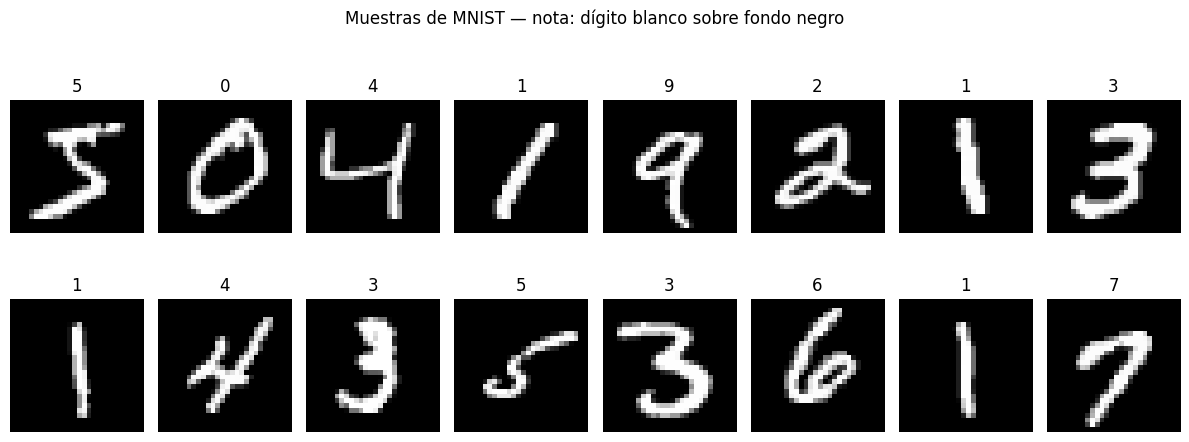


Ejemplos por clase (entrenamiento): [4932 5678 4968 5101 4859 4506 4951 5175 4842 4988]




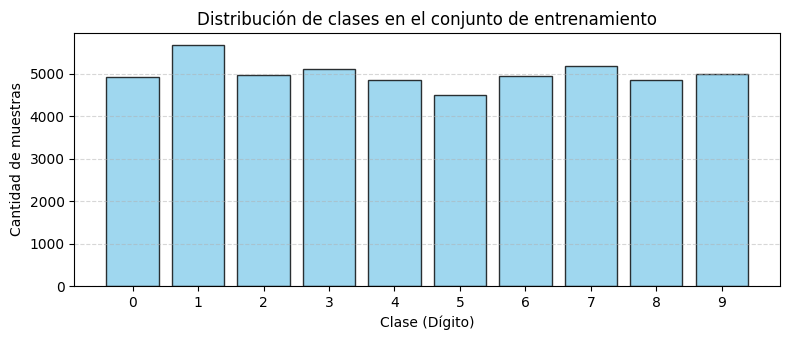

In [ ]:
# Revisar los datos que componen el conjunto de entrenamiento: 16 muestras aleatorias

fig, axes = plt.subplots(2, 8, figsize=(12, 5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(int(y_train[i])); ax.axis("off")
plt.suptitle("Muestras de MNIST — nota: dígito blanco sobre fondo negro")
plt.tight_layout(); plt.show()

# Imprimir el bincount actual

counts = np.bincount(y_train)
print("\nEjemplos por clase (entrenamiento):", counts)
print("\n")

# Agregar un gráfico de barras (histograma de clases) para revisar el balanceo

plt.figure(figsize=(8, 3.5))
plt.bar(range(10), counts, color="skyblue", edgecolor="black", alpha=0.8)
plt.title("Distribución de clases en el conjunto de entrenamiento")
plt.xlabel("Clase (Dígito)")
plt.ylabel("Cantidad de muestras")
plt.xticks(range(10))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Preprocesamiento: normalización

Las redes neuronales entrenan mejor cuando las entradas son pequeñas y de escala similar, así que llevamos los píxeles
de `0..255` a `0.0..1.0` y añadimos un eje de canal (`28×28` → `28×28×1`), porque las capas convolucionales lo esperan ya que funcionan con tensores.

⚠️ **Lo que hagamos aquí, el ESP32 debe hacerlo exactamente igual** con cada imagen de la cámara.
Lo dejamos por escrito como un "contrato de preprocesamiento":

| Paso | Python (aquí) | ESP32 |
|---|---|---|
| Tamaño | 28×28 | recortar + redimensionar el cuadro de la cámara a 28×28 |
| Polaridad | dígito blanco sobre negro | invertir la imagen de la cámara |
| Escala | `x / 255.0` | igual, y luego cuantizar a int8  |

In [ ]:
def preprocess(x):
    # uint8 [0,255] (N,28,28) -> float32 [0,1] (N,28,28,1)
    return (x.astype("float32") / 255.0)[..., np.newaxis]

x_train_p, x_val_p, x_test_p = preprocess(x_train), preprocess(x_val), preprocess(x_test)
print(f"Shape del conjunto de entrenamiento:: {x_train_p.shape}, dtype: {x_train_p.dtype}, min: {x_train_p.min()}, max: {x_train_p.max()}")

(50000, 28, 28, 1) float32 0.0 1.0


---
## 2. Modelos base 

Comparamos dos arquitecturas. En un microcontrolador, la exactitud **no es la única métrica**:
cada parámetro cuesta memoria flash y cada activación cuesta RAM.

**Modelo A — red densa pequeña (MLP):** aplana la imagen e ignora su estructura 2-D.
Es simple, pero los parámetros crecen como `píxeles_de_entrada × neuronas` (784 × 32 ≈ 25k pesos solo en la primera capa).

**Modelo B — CNN pequeña:** los filtros convolucionales pequeños (3×3) se *comparten* en toda la imagen, así que
detectan trazos en cualquier posición con muy pocos pesos. Normalmente es más exacta *y* más pequeña. El costo es más
**cómputo** (cada filtro se desliza por todas las posiciones), lo cual no es problema con 28×28.

In [ ]:
def build_mlp():
    return tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28, 1)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ], name="mlp")

def build_tiny_cnn():
    return tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(8, 3, activation="relu"),    # 28x28 -> 26x26x8
        tf.keras.layers.MaxPooling2D(),                     # -> 13x13x8
        tf.keras.layers.Conv2D(16, 3, activation="relu"),   # -> 11x11x16
        tf.keras.layers.MaxPooling2D(),                     # -> 5x5x16
        tf.keras.layers.Flatten(),                          # -> 400
        tf.keras.layers.Dense(10, activation="softmax"),
    ], name="tiny_cnn")

# NOTA: solo operaciones estándar (Conv2D, MaxPool, Dense/FullyConnected, Softmax, Reshape).
# Toda operación usada aquí debe existir también en TensorFlow Lite Micro en el ESP32.

for builder in (build_mlp, build_tiny_cnn):
    builder().summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Model: "tiny_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         4,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,258 (20.54 KB)

 Trainable params: 5,258 (20.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCHS = 5
BATCH = 128
results = {}

for builder in (build_mlp, build_tiny_cnn):
    tf.random.set_seed(SEED)  # mismas condiciones de inicialización para cada modelo
    model = builder()
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    hist = model.fit(x_train_p, y_train, validation_data=(x_val_p, y_val),
                     epochs=EPOCHS, batch_size=BATCH, verbose=2)
    params = model.count_params()
    results[model.name] = {
        "model": model,
        "history": hist.history,
        "val_acc": hist.history["val_accuracy"][-1],
        "params": params,
        # tamaño aproximado: float32 = 4 bytes/peso, int8 = 1 byte/peso
        "kb_float32": params * 4 / 1024,
        "kb_int8_est": params / 1024,
    }

Epoch 1/5
391/391 - 9s - 22ms/step - accuracy: 0.8514 - loss: 0.5356 - val_accuracy: 0.9232 - val_loss: 0.2750
Epoch 2/5
391/391 - 2s - 5ms/step - accuracy: 0.9260 - loss: 0.2638 - val_accuracy: 0.9375 - val_loss: 0.2216
Epoch 3/5
391/391 - 2s - 5ms/step - accuracy: 0.9389 - loss: 0.2158 - val_accuracy: 0.9465 - val_loss: 0.1927
Epoch 4/5
391/391 - 2s - 5ms/step - accuracy: 0.9469 - loss: 0.1852 - val_accuracy: 0.9527 - val_loss: 0.1735
Epoch 5/5
391/391 - 2s - 5ms/step - accuracy: 0.9530 - loss: 0.1630 - val_accuracy: 0.9565 - val_loss: 0.1597
Epoch 1/5
391/391 - 5s - 12ms/step - accuracy: 0.8610 - loss: 0.4975 - val_accuracy: 0.9548 - val_loss: 0.1618
Epoch 2/5
391/391 - 2s - 6ms/step - accuracy: 0.9593 - loss: 0.1369 - val_accuracy: 0.9667 - val_loss: 0.1125
Epoch 3/5
391/391 - 3s - 7ms/step - accuracy: 0.9689 - loss: 0.1019 - val_accuracy: 0.9733 - val_loss: 0.0947
Epoch 4/5
391/391 - 3s - 7ms/step - accuracy: 0.9739 - loss: 0.0860 - val_accuracy: 0.9768 - val_loss: 0.0853
Epoch 5/

modelo       params  KB float32  KB int8 (est)  exact. val
mlp           25450        99.4           24.9      0.9565
tiny_cnn       5258        20.5            5.1      0.9791


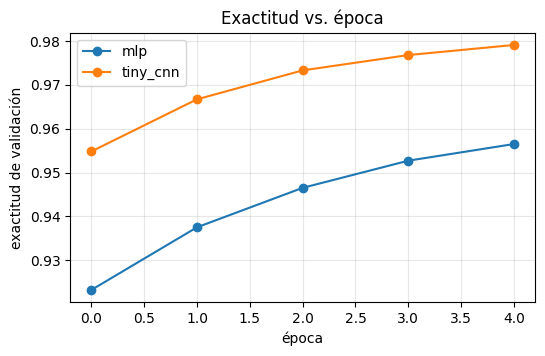

In [ ]:
print(f"{'modelo':10s} {'params':>8s} {'KB float32':>11s} {'KB int8 (est)':>14s} {'exact. val':>11s}")
for name, r in results.items():
    print(f"{name:10s} {r['params']:8d} {r['kb_float32']:11.1f} {r['kb_int8_est']:14.1f} {r['val_acc']:11.4f}")

plt.figure(figsize=(6, 3.5))
for name, r in results.items():
    plt.plot(r["history"]["val_accuracy"], marker="o", label=name)
plt.xlabel("época"); plt.ylabel("exactitud de validación"); plt.legend(); plt.grid(alpha=.3)
plt.title("Exactitud vs. época"); plt.show()

In [ ]:
# Verificación final con el conjunto de PRUEBA — se hace una sola vez, con el modelo elegido.
chosen = results["tiny_cnn"]["model"]
test_loss, test_acc = chosen.evaluate(x_test_p, y_test, verbose=0)
print(f"exactitud de prueba tiny_cnn: {test_acc:.4f}")

chosen.save(os.path.join(OUT_DIR, "tiny_cnn_float.keras"))
print("Modelo float guardado en", OUT_DIR)

exactitud de prueba tiny_cnn: 0.9801
Modelo float guardado en artefactos


## 3. Robustez: aumento de datos  *(Etapa 3)*

**Problema (cambio de dominio):** MNIST tiene dígitos centrados, de grosor uniforme, blanco puro sobre negro puro.
Una imagen de cámara llega descentrada, girada, borrosa, con fondo gris, iluminación desigual y ruido.

**Solución en esta etapa:** entrenar con versiones deformadas de MNIST (nuevas en cada época) y medir con un
conjunto de validación/prueba "tipo cámara" generado una sola vez con semilla fija.

⚠️ Ese conjunto es una aproximación optimista; la prueba real son fotos de la ESP32-CAM (Etapa 7).
La otra mitad de la solución, hacer que la imagen de la cámara se parezca a MNIST, es el preprocesamiento de la Etapa 5.

In [ ]:
from scipy import ndimage

# Parámetros de las deformaciones "tipo cámara".
# Cada valor es el MÁXIMO (o el rango) de una deformación; para cada imagen se sortea un valor al azar.
PARAMS_CAMARA = dict(
    rot_max=15,             # rotación: ±15 grados (papel o cámara ligeramente girados)
    escala=(0.75, 1.15),    # tamaño: el dígito ocupa entre 75 % y 115 % de lo normal (distancia a la cámara)
    desp_max=3,             # desplazamiento: ±3 px (el dígito no queda perfectamente centrado)
    p_grosor=0.5,           # prob. de cambiar el grosor del trazo (lápiz vs. marcador)
    sigma_max=1.0,          # desenfoque gaussiano máximo, en píxeles (enfoque imperfecto)
    contraste=(0.5, 1.0),   # el trazo no llega a blanco puro (poca luz, tinta gris)
    fondo_max=0.25,         # el fondo no es negro puro (papel gris tras invertir)
    gradiente_max=0.10,     # iluminación desigual: el fondo es más claro de un lado
    ruido_max=0.08,         # ruido del sensor (desviación estándar máxima)
)

def deformar(x, rng, rot_max=0, escala=(1, 1), desp_max=0, p_grosor=0, sigma_max=0,
             contraste=(1, 1), fondo_max=0, gradiente_max=0, ruido_max=0, bloque=5000):
    """Aplica deformaciones aleatorias 'tipo cámara' a un lote de imágenes.

    x   : float32 (N, 28, 28, 1) en [0, 1], dígito blanco sobre negro (salida de preprocess).
    rng : np.random.Generator, controla el azar (misma semilla -> mismas deformaciones).
    Por defecto no deforma nada; se activan las deformaciones pasando parámetros,
    por ejemplo: deformar(x, rng, **PARAMS_CAMARA).
    """
    salida = np.empty_like(x)
    filas, cols = np.meshgrid(np.arange(28), np.arange(28), indexing="ij")
    c0 = 13.5  # centro de la imagen

    for ini in range(0, len(x), bloque):          # por bloques, para no agotar la RAM
        xb = x[ini:ini + bloque, :, :, 0]
        n = len(xb)

        # 1) Geometría: rotación + escala + desplazamiento (una transformación afín por imagen).
        #    Para cada píxel de SALIDA calculamos de qué punto de la imagen ORIGINAL viene
        #    ("mapeo inverso") e interpolamos ahí.
        ang = np.deg2rad(rng.uniform(-rot_max, rot_max, n))[:, None, None]
        esc = rng.uniform(escala[0], escala[1], n)[:, None, None]
        dy = rng.uniform(-desp_max, desp_max, n)[:, None, None]
        dx = rng.uniform(-desp_max, desp_max, n)[:, None, None]
        y = filas - c0 - dy
        xx = cols - c0 - dx
        y_orig = ( np.cos(ang) * y + np.sin(ang) * xx) / esc + c0
        x_orig = (-np.sin(ang) * y + np.cos(ang) * xx) / esc + c0
        idx = np.broadcast_to(np.arange(n)[:, None, None], y_orig.shape)
        xb = ndimage.map_coordinates(xb, [idx, y_orig, x_orig], order=1, cval=0.0)

        # 2) Grosor del trazo: dilatar (más grueso) o erosionar (más delgado).
        sorteo = rng.random(n)
        engrosar = sorteo < p_grosor / 2
        adelgazar = (sorteo >= p_grosor / 2) & (sorteo < p_grosor)
        if engrosar.any():
            xb[engrosar] = ndimage.grey_dilation(xb[engrosar], size=(1, 2, 2))
        if adelgazar.any():
            xb[adelgazar] = ndimage.grey_erosion(xb[adelgazar], size=(1, 2, 2))

        # 3) Desenfoque: tres niveles (nada, suave, fuerte) asignados al azar.
        if sigma_max > 0:
            nivel = rng.integers(0, 3, n)
            for k, sigma in [(1, sigma_max / 2), (2, sigma_max)]:
                m = nivel == k
                if m.any():
                    xb[m] = ndimage.gaussian_filter(xb[m], sigma=(0, sigma, sigma))

        # 4) Fotometría: contraste reducido, fondo gris, iluminación desigual y ruido.
        con = rng.uniform(contraste[0], contraste[1], n)[:, None, None]
        fondo = rng.uniform(0, fondo_max, n)[:, None, None]
        direc = rng.uniform(0, 2 * np.pi, n)[:, None, None]
        grad = rng.uniform(0, gradiente_max, n)[:, None, None]
        rampa = (np.cos(direc) * (filas - c0) + np.sin(direc) * (cols - c0)) / c0  # de -1 a 1 aprox.
        ruido = rng.normal(0, 1, xb.shape) * rng.uniform(0, ruido_max, n)[:, None, None]
        xb = fondo + con * xb + grad * rampa + ruido

        salida[ini:ini + n, :, :, 0] = np.clip(xb, 0.0, 1.0)

    return salida

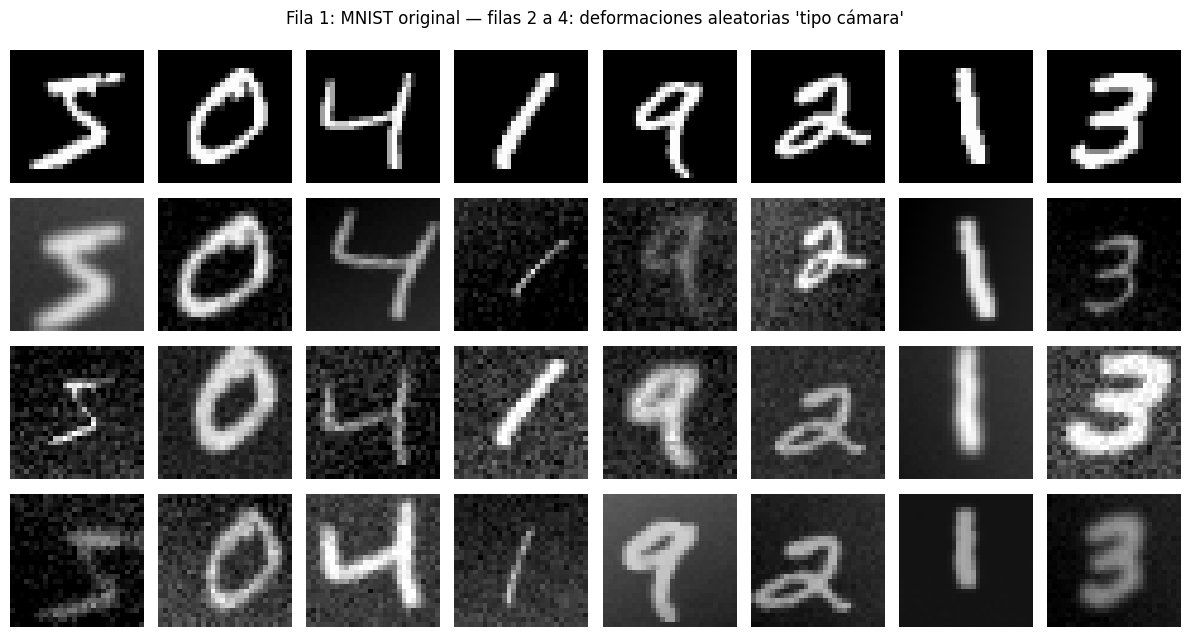

In [ ]:
# Mira los datos antes de entrenar. Fila 1: originales. Filas 2–4: los MISMOS dígitos
# con tres deformaciones aleatorias distintas.
# vmin=0, vmax=1 es importante: sin eso, imshow reescala cada imagen y "esconde"
# justamente los cambios de contraste y de fondo que queremos ver.
rng_vis = np.random.default_rng(0)
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for fila in range(4):
    imgs = x_train_p[:8] if fila == 0 else deformar(x_train_p[:8], rng_vis, **PARAMS_CAMARA)
    for col in range(8):
        axes[fila, col].imshow(imgs[col, :, :, 0], cmap="gray", vmin=0, vmax=1)
        axes[fila, col].axis("off")
plt.suptitle("Fila 1: MNIST original — filas 2 a 4: deformaciones aleatorias 'tipo cámara'")
plt.tight_layout(); plt.show()

In [ ]:
# Conjuntos de evaluación "tipo cámara": se generan UNA sola vez, con semillas fijas, y no cambian.
# Son versiones deformadas de validación y prueba (dígitos que el modelo nunca vio al entrenar).
x_val_cam  = deformar(x_val_p,  np.random.default_rng(SEED + 1), **PARAMS_CAMARA)
x_test_cam = deformar(x_test_p, np.random.default_rng(SEED + 2), **PARAMS_CAMARA)

base = results["tiny_cnn"]["model"]   # la CNN de la sección 2, entrenada SIN aumento
_, base_val_limpia = base.evaluate(x_val_p,   y_val, verbose=0)
_, base_val_cam    = base.evaluate(x_val_cam, y_val, verbose=0)
print(f"tiny_cnn sin aumento → validación limpia: {base_val_limpia:.4f} | validación tipo cámara: {base_val_cam:.4f}")
print(f"Caída por cambio de dominio: {100 * (base_val_limpia - base_val_cam):.1f} puntos porcentuales")

tiny_cnn sin aumento → validación limpia: 0.9791 | validación tipo cámara: 0.6952
Caída por cambio de dominio: 28.4 puntos porcentuales


In [ ]:
def build_cnn_mediana():
    # Igual que tiny_cnn pero con el DOBLE de filtros: más capacidad para aprender
    # dígitos deformados. Sigue siendo diminuta (~12,5 KB en int8).
    return tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(16, 3, activation="relu"),   # -> 26x26x16
        tf.keras.layers.MaxPooling2D(),                     # -> 13x13x16
        tf.keras.layers.Conv2D(32, 3, activation="relu"),   # -> 11x11x32
        tf.keras.layers.MaxPooling2D(),                     # -> 5x5x32
        tf.keras.layers.Flatten(),                          # -> 800
        tf.keras.layers.Dense(10, activation="softmax"),
    ], name="cnn_mediana")

EPOCHS_AUG = 15   # con aumento la tarea es más difícil: hacen falta más épocas que las 5 de la sección 2

def entrenar_con_aumento(builder, nombre, epocas=EPOCHS_AUG):
    tf.random.set_seed(SEED)              # misma inicialización de pesos en cada corrida
    rng = np.random.default_rng(SEED)     # mismas deformaciones en cada corrida
    modelo = builder()
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist = {"val_limpia": [], "val_cam": []}
    for ep in range(epocas):
        # La clave del aumento: en cada época el modelo ve una versión DISTINTA de cada dígito,
        # así no puede memorizar píxeles y tiene que aprender la forma del número.
        x_ep = deformar(x_train_p, rng, **PARAMS_CAMARA)
        modelo.fit(x_ep, y_train, epochs=1, batch_size=BATCH, verbose=0)
        _, a_limpia = modelo.evaluate(x_val_p,   y_val, verbose=0)
        _, a_cam    = modelo.evaluate(x_val_cam, y_val, verbose=0)
        hist["val_limpia"].append(a_limpia)
        hist["val_cam"].append(a_cam)
        print(f"{nombre:16s} época {ep + 1:2d}/{epocas} | val limpia {a_limpia:.4f} | val cámara {a_cam:.4f}")
    return modelo, hist

modelos = {"tiny_cnn": base}   # nombre -> modelo (incluimos la base para comparar)
historiales = {}
for builder, nombre in [(build_tiny_cnn, "tiny_cnn+aum"), (build_cnn_mediana, "cnn_mediana+aum")]:
    modelos[nombre], historiales[nombre] = entrenar_con_aumento(builder, nombre)

tiny_cnn+aum     época  1/15 | val limpia 0.9408 | val cámara 0.7838
tiny_cnn+aum     época  2/15 | val limpia 0.9489 | val cámara 0.8402
tiny_cnn+aum     época  3/15 | val limpia 0.9539 | val cámara 0.8627
tiny_cnn+aum     época  4/15 | val limpia 0.9578 | val cámara 0.8745
tiny_cnn+aum     época  5/15 | val limpia 0.9591 | val cámara 0.8813
tiny_cnn+aum     época  6/15 | val limpia 0.9637 | val cámara 0.8768
tiny_cnn+aum     época  7/15 | val limpia 0.9657 | val cámara 0.8926
tiny_cnn+aum     época  8/15 | val limpia 0.9669 | val cámara 0.8981
tiny_cnn+aum     época  9/15 | val limpia 0.9727 | val cámara 0.9010
tiny_cnn+aum     época 10/15 | val limpia 0.9701 | val cámara 0.9038
tiny_cnn+aum     época 11/15 | val limpia 0.9721 | val cámara 0.9058
tiny_cnn+aum     época 12/15 | val limpia 0.9704 | val cámara 0.9012
tiny_cnn+aum     época 13/15 | val limpia 0.9721 | val cámara 0.9094
tiny_cnn+aum     época 14/15 | val limpia 0.9749 | val cámara 0.9118
tiny_cnn+aum     época 15/15 | val

modelo            params  KB int8  val limpia  val cámara
tiny_cnn            5258      5.1      0.9791      0.6952
tiny_cnn+aum        5258      5.1      0.9760      0.9132
cnn_mediana+aum    12810     12.5      0.9825      0.9360


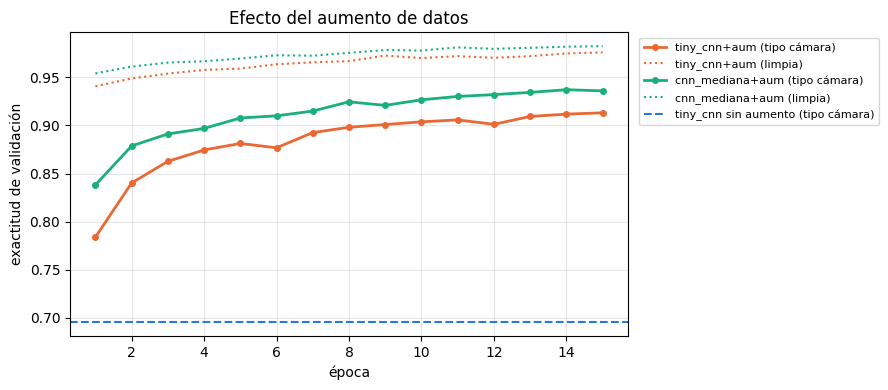

In [ ]:
# Tabla comparativa — todo en VALIDACIÓN (la prueba se reserva para el final).
COLORES = {"tiny_cnn": "#2a78d6", "tiny_cnn+aum": "#eb6834", "cnn_mediana+aum": "#1baf7a"}
val_cam = {}
print(f"{'modelo':16s} {'params':>7s} {'KB int8':>8s} {'val limpia':>11s} {'val cámara':>11s}")
for nombre, m in modelos.items():
    _, a_limpia = m.evaluate(x_val_p, y_val, verbose=0)
    _, val_cam[nombre] = m.evaluate(x_val_cam, y_val, verbose=0)
    print(f"{nombre:16s} {m.count_params():7d} {m.count_params() / 1024:8.1f} {a_limpia:11.4f} {val_cam[nombre]:11.4f}")

# Curvas de aprendizaje: línea continua = tipo cámara, punteada = MNIST limpio
plt.figure(figsize=(9, 4))
for nombre, h in historiales.items():
    ep = range(1, len(h["val_cam"]) + 1)
    plt.plot(ep, h["val_cam"], color=COLORES[nombre], lw=2, marker="o", ms=4, label=f"{nombre} (tipo cámara)")
    plt.plot(ep, h["val_limpia"], color=COLORES[nombre], lw=1.5, ls=":", label=f"{nombre} (limpia)")
plt.axhline(val_cam["tiny_cnn"], color=COLORES["tiny_cnn"], lw=1.5, ls="--", label="tiny_cnn sin aumento (tipo cámara)")
plt.xlabel("época"); plt.ylabel("exactitud de validación"); plt.title("Efecto del aumento de datos")
plt.grid(alpha=.3); plt.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

In [ ]:
# Selección del modelo final: se decide con la VALIDACIÓN tipo cámara, nunca con la prueba.
# Regla: entre los modelos a menos de 1 punto del mejor, elegir el de MENOS parámetros
# (en un microcontrolador cada KB y cada milisegundo cuentan).
mejor = max(val_cam.values())
candidatos = [n for n in modelos if val_cam[n] >= mejor - 0.01]
NOMBRE_FINAL = min(candidatos, key=lambda n: modelos[n].count_params())
modelo_final = modelos[NOMBRE_FINAL]
print("Modelo elegido:", NOMBRE_FINAL, "| parámetros:", modelo_final.count_params())

# Reporte final en PRUEBA (se hace una sola vez). Incluimos la base como referencia.
print(f"\n{'modelo':16s} {'prueba limpia':>14s} {'prueba cámara':>14s}")
for nombre in dict.fromkeys(["tiny_cnn", NOMBRE_FINAL]):   # dict.fromkeys evita repetir si coinciden
    m = modelos[nombre]
    t_limpia = m.evaluate(x_test_p,   y_test, verbose=0)[1]
    t_cam    = m.evaluate(x_test_cam, y_test, verbose=0)[1]
    print(f"{nombre:16s} {t_limpia:14.4f} {t_cam:14.4f}")

ruta = os.path.join(OUT_DIR, "modelo_final_float.keras")
modelo_final.save(ruta)
print("\nGuardado:", ruta, "→ es el que cuantizaremos en la Etapa 4")

Modelo elegido: cnn_mediana+aum | parámetros: 12810

modelo            prueba limpia  prueba cámara
tiny_cnn                 0.9801         0.6865
cnn_mediana+aum          0.9835         0.9378

Guardado: artefactos/modelo_final_float.keras → es el que cuantizaremos en la Etapa 4


## 4. Cuantización int8 y exportación a C  *(Etapa 4)*

**Cuantización afín:** real ≈ escala × (q − punto_cero), con q ∈ [−128, 127].
- Pesos: cuantizados por canal. Activaciones: calibradas con un *conjunto representativo* (mitad limpio, mitad tipo cámara).
- Entrada y salida también en int8: el ESP32 no hace ninguna operación en punto flotante.

Salidas: `mnist_int8.tflite` (modelo) y `model_data.h` (el mismo modelo como arreglo de C, para Arduino).

In [ ]:
import keras

# Intérprete (LiteRT si está instalado; si no, el de TF) y tipo de resolver SIN aceleradores.
try:
    from ai_edge_litert.interpreter import Interpreter, OpResolverType
except ImportError:
    Interpreter = tf.lite.Interpreter
    OpResolverType = tf.lite.experimental.OpResolverType

def operaciones_del_modelo(modelo_bytes):
    """Operaciones del ARCHIVO .tflite, sin el acelerador XNNPACK de Python: lo que verá el ESP32."""
    it = Interpreter(model_content=modelo_bytes,
                     experimental_op_resolver_type=OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
    it.allocate_tensors()
    return sorted({op["op_name"] for op in it._get_ops_details()})

REGISTRADAS_ETAPA0 = {"CONV_2D", "MAX_POOL_2D", "RESHAPE", "FULLY_CONNECTED", "SOFTMAX"}

# 1) Exportar declarando EXPLÍCITAMENTE la forma de entrada [1, 28, 28, 1] (lote fijo de 1).
#    Con todas las formas conocidas, el convertidor no necesita SHAPE / STRIDED_SLICE / PACK.
RUTA_SAVEDMODEL = os.path.join(OUT_DIR, "modelo_final_savedmodel_lote1")
archivo = keras.export.ExportArchive()
archivo.track(modelo_final)
archivo.add_endpoint(name="serve", fn=modelo_final.call,
                     input_signature=[tf.TensorSpec([1, 28, 28, 1], tf.float32)])
archivo.write_out(RUTA_SAVEDMODEL)

# 2) Conjunto REPRESENTATIVO: imágenes de ENTRENAMIENTO, mitad limpias y mitad "tipo cámara".
rng_rep = np.random.default_rng(SEED + 10)
idx_rep = rng_rep.choice(len(x_train_p), 500, replace=False)
x_rep = np.concatenate([x_train_p[idx_rep[:250]],
                        deformar(x_train_p[idx_rep[250:]], rng_rep, **PARAMS_CAMARA)])

def dataset_representativo():
    for i in range(len(x_rep)):
        yield [x_rep[i:i + 1]]     # una imagen por llamada: forma (1, 28, 28, 1), float32

def nuevo_convertidor():
    return tf.lite.TFLiteConverter.from_saved_model(RUTA_SAVEDMODEL, signature_keys=["serve"])

# 3a) Conversión SIN cuantizar (float32): solo para comparar tamaños.
modelo_float_tflite = nuevo_convertidor().convert()

# 3b) Conversión con cuantización entera COMPLETA (int8).
conv = nuevo_convertidor()
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = dataset_representativo
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
modelo_int8 = conv.convert()

ruta_tflite = os.path.join(OUT_DIR, "mnist_int8.tflite")
with open(ruta_tflite, "wb") as f:
    f.write(modelo_int8)

print(f".tflite float32: {len(modelo_float_tflite) / 1024:6.1f} KB")
print(f".tflite int8   : {len(modelo_int8) / 1024:6.1f} KB  → {ruta_tflite}")

# 4) Comprobación automática: ¿el archivo usa solo las operaciones que el firmware registra?
ops = operaciones_del_modelo(modelo_int8)
print("Operaciones del archivo:", ops)
sobran = set(ops) - REGISTRADAS_ETAPA0
print("✅ Coincide con el firmware" if not sobran else f"⚠️ Operaciones de más: {sorted(sobran)}")

Saved artifact at 'artefactos/modelo_final_savedmodel_lote1'. The following endpoints are available:

* Endpoint 'serve'
  inputs (POSITIONAL_OR_KEYWORD): TensorSpec(shape=(1, 28, 28, 1), dtype=tf.float32, name=None)
  training (POSITIONAL_OR_KEYWORD): Literal[None]
  mask (POSITIONAL_OR_KEYWORD): Literal[None]
Output Type:
  TensorSpec(shape=(1, 10), dtype=tf.float32, name=None)
Captures:
  138844214755152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138844214753424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138844214751504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138844214752080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138844214754960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138844214751312: TensorSpec(shape=(), dtype=tf.resource, name=None)
.tflite float32:   52.7 KB
.tflite int8   :   17.1 KB  → artefactos/mnist_int8.tflite
Operaciones del archivo: ['CONV_2D', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'RESHAPE', 'SOFTMAX']
✅ Coinci

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
interp = Interpreter(model_content=modelo_int8)
interp.allocate_tensors()
ent = interp.get_input_details()[0]
sal = interp.get_output_details()[0]
ESC_ENT, ZP_ENT = ent["quantization"]   # real = escala * (q - punto_cero)
ESC_SAL, ZP_SAL = sal["quantization"]

print(f"ENTRADA: forma {ent['shape'].tolist()}, tipo {ent['dtype'].__name__}, "
      f"escala = {ESC_ENT:.8f} (= 1/{1 / ESC_ENT:.1f}), punto cero = {ZP_ENT}")
print(f"SALIDA : forma {sal['shape'].tolist()}, tipo {sal['dtype'].__name__}, "
      f"escala = {ESC_SAL:.8f} (= 1/{1 / ESC_SAL:.1f}), punto cero = {ZP_SAL}")

# Así se cuantiza un píxel de la cámara (0–255) siguiendo el contrato de preprocesamiento.
print("\nCuantización de la ENTRADA (lo que hará el ESP32 con cada píxel):")
for pixel in [0, 64, 128, 255]:
    x = pixel / 255.0                                       # contrato: escalar a 0..1
    q = int(np.clip(np.round(x / ESC_ENT) + ZP_ENT, -128, 127))
    print(f"  píxel {pixel:3d} → x = {x:.3f} → q = {q:4d}")

# Y así se interpreta la SALIDA: de int8 a probabilidad.
print("\nDescuantización de la SALIDA:")
for q in [-128, 0, 127]:
    print(f"  q = {q:4d} → probabilidad = {ESC_SAL * (q - ZP_SAL):.3f}")

# Operaciones que usa el modelo: TODAS deben estar registradas en el firmware.
# (_get_ops_details es una función interna del intérprete, pero muy útil para esto.)
ops = operaciones_del_modelo(modelo_int8)
REGISTRADAS_ETAPA0 = {"CONV_2D", "MAX_POOL_2D", "RESHAPE", "FULLY_CONNECTED", "SOFTMAX"}
print("\nOperaciones del modelo:", ops)
faltan = set(ops) - REGISTRADAS_ETAPA0
print("✅ Todas ya están registradas en el firmware de la Etapa 0" if not faltan
      else f"⚠️ Habrá que registrar en el firmware: {sorted(faltan)}")

ENTRADA: forma [1, 28, 28, 1], tipo int8, escala = 0.00392157 (= 1/255.0), punto cero = -128
SALIDA : forma [1, 10], tipo int8, escala = 0.00390625 (= 1/256.0), punto cero = -128

Cuantización de la ENTRADA (lo que hará el ESP32 con cada píxel):
  píxel   0 → x = 0.000 → q = -128
  píxel  64 → x = 0.251 → q =  -64
  píxel 128 → x = 0.502 → q =    0
  píxel 255 → x = 1.000 → q =  127

Descuantización de la SALIDA:
  q = -128 → probabilidad = 0.000
  q =    0 → probabilidad = 0.500
  q =  127 → probabilidad = 0.996

Operaciones del modelo: ['CONV_2D', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'RESHAPE', 'SOFTMAX']
✅ Todas ya están registradas en el firmware de la Etapa 0


In [ ]:
def predecir_int8(modelo_bytes, x):
    """Clasifica con el modelo int8 exactamente como lo hará el ESP32: cuantizar → invocar → argmax."""
    it = Interpreter(model_content=modelo_bytes)
    it.allocate_tensors()
    e, s = it.get_input_details()[0], it.get_output_details()[0]
    escala, punto_cero = e["quantization"]
    xq = np.clip(np.round(x / escala) + punto_cero, -128, 127).astype(np.int8)
    preds = np.empty(len(x), dtype=np.int64)
    for i in range(len(x)):                  # una imagen a la vez, como en el microcontrolador
        it.set_tensor(e["index"], xq[i:i + 1])
        it.invoke()
        # argmax directo sobre los int8: descuantizar no cambia el orden (escala > 0)
        preds[i] = np.argmax(it.get_tensor(s["index"])[0])
    return preds

conjuntos = {
    "val limpia":    (x_val_p,    y_val),
    "val cámara":    (x_val_cam,  y_val),
    "prueba limpia": (x_test_p,   y_test),
    "prueba cámara": (x_test_cam, y_test),
}
exact_int8 = {}
print(f"{'conjunto':14s} {'float32':>8s} {'int8':>8s} {'diferencia':>11s} {'coinciden':>10s}")
for nombre, (x, y) in conjuntos.items():
    p_float = modelo_final.predict(x, verbose=0).argmax(axis=1)
    p_int8 = predecir_int8(modelo_int8, x)
    a_f, a_q = (p_float == y).mean(), (p_int8 == y).mean()
    exact_int8[nombre] = a_q
    print(f"{nombre:14s} {a_f:8.4f} {a_q:8.4f} {100 * (a_q - a_f):+9.2f}pp {(p_float == p_int8).mean():10.4f}")

conjunto        float32     int8  diferencia  coinciden
val limpia       0.9825   0.9823     -0.02pp     0.9980
val cámara       0.9360   0.9351     -0.09pp     0.9899
prueba limpia    0.9835   0.9844     +0.09pp     0.9983
prueba cámara    0.9378   0.9368     -0.10pp     0.9890


In [ ]:
import datetime

def escribir_header_c(datos, ruta, nombre, comentarios):
    """Convierte los bytes del .tflite en un arreglo de C (equivale a `xxd -i`)."""
    filas = ["  " + ", ".join(f"0x{b:02x}" for b in datos[i:i + 12]) + ","
             for i in range(0, len(datos), 12)]
    texto = (
        "// ARCHIVO GENERADO AUTOMÁTICAMENTE por entrenamiento/mnist_tinyml_entrenamiento.ipynb\n"
        "// NO EDITAR A MANO: si cambias el modelo, vuelve a ejecutar el notebook.\n//\n"
        + "".join(f"// {c}\n" for c in comentarios)
        + "\n#pragma once\n\n"
        "// 'const' hace que el arreglo quede en la memoria FLASH (no ocupa RAM).\n"
        "// alignas(16): TFLite Micro lee el modelo directamente desde aquí; la alineación\n"
        "// evita accesos desalineados a su estructura interna (flatbuffer).\n"
        f"alignas(16) const unsigned char {nombre}[] = {{\n"
        + "\n".join(filas)
        + f"\n}};\nconst unsigned int {nombre}_len = {len(datos)};\n"
    )
    with open(ruta, "w", encoding="utf-8") as f:
        f.write(texto)
    return texto

ruta_h = os.path.join(OUT_DIR, "model_data.h")
texto = escribir_header_c(modelo_int8, ruta_h, "g_modelo_mnist", [
    f"Modelo : {NOMBRE_FINAL} | cuantización int8 completa | {len(modelo_int8)} bytes",
    f"Generado: {datetime.date.today()} con TensorFlow {tf.__version__}",
    f"Entrada: int8 {ent['shape'].tolist()}  escala={ESC_ENT:.8f}  punto_cero={ZP_ENT}",
    f"Salida : int8 {sal['shape'].tolist()}  escala={ESC_SAL:.8f}  punto_cero={ZP_SAL}",
    f"Exactitud int8 en prueba: limpia={exact_int8['prueba limpia']:.4f}  tipo cámara={exact_int8['prueba cámara']:.4f}",
])
lineas = texto.splitlines()
print("\n".join(lineas[:18]), "\n  ...\n" + "\n".join(lineas[-3:]))
print(f"\nGuardado: {ruta_h} ({os.path.getsize(ruta_h) / 1024:.0f} KB de texto → {len(modelo_int8) / 1024:.1f} KB en la flash)")

// ARCHIVO GENERADO AUTOMÁTICAMENTE por entrenamiento/mnist_tinyml_entrenamiento.ipynb
// NO EDITAR A MANO: si cambias el modelo, vuelve a ejecutar el notebook.
//
// Modelo : cnn_mediana+aum | cuantización int8 completa | 17504 bytes
// Generado: 2026-10-09 con TensorFlow 2.21.0
// Entrada: int8 [1, 28, 28, 1]  escala=0.00392157  punto_cero=-128
// Salida : int8 [1, 10]  escala=0.00390625  punto_cero=-128
// Exactitud int8 en prueba: limpia=0.9844  tipo cámara=0.9368

#pragma once

// 'const' hace que el arreglo quede en la memoria FLASH (no ocupa RAM).
// alignas(16): TFLite Micro lee el modelo directamente desde aquí; la alineación
// evita accesos desalineados a su estructura interna (flatbuffer).
alignas(16) const unsigned char g_modelo_mnist[] = {
  0x20, 0x00, 0x00, 0x00, 0x54, 0x46, 0x4c, 0x33, 0x00, 0x00, 0x00, 0x00,
  0x14, 0x00, 0x20, 0x00, 0x1c, 0x00, 0x18, 0x00, 0x14, 0x00, 0x10, 0x00,
  0x0c, 0x00, 0x00, 0x00, 0x08, 0x00, 0x04, 0x00, 0x14, 0x00, 0x00, 0x00, 
  ...
  0x03,

---
## Descargar los resultados (Colab)

Ejecuta esto después de la Etapa 4 para descargar los archivos a tu computador; luego cópialos en el repositorio.

In [ ]:
if EN_COLAB:
    from google.colab import files
    for f in ["mnist_int8.tflite", "model_data.h"]:
        path = os.path.join(OUT_DIR, f)
        if os.path.exists(path):
            files.download(path)
        else:
            print("Aún no generado:", path)
else:
    print("No estás en Colab: los archivos están en", os.path.abspath(OUT_DIR))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>